# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [3]:


df = pd.read_csv('AviationData_cleaned.csv', encoding='latin1')

print(df.shape)

(17879, 29)


In [4]:
print(df.shape)
print(df.columns.tolist())

(17879, 29)
['Event.Id', 'Investigation.Type', 'Accident.Number', 'Event.Date', 'Location', 'Country', 'Latitude', 'Longitude', 'Airport.Code', 'Airport.Name', 'Injury.Severity', 'Aircraft.damage', 'Aircraft.Category', 'Registration.Number', 'Make', 'Model', 'Amateur.Built', 'Number.of.Engines', 'Engine.Type', 'FAR.Description', 'Purpose.of.flight', 'Total.Fatal.Injuries', 'Total.Serious.Injuries', 'Total.Minor.Injuries', 'Total.Uninjured', 'Weather.Condition', 'Broad.phase.of.flight', 'Report.Status', 'Publication.Date']


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [5]:
# Replace missing injury counts with zero
injury_columns = [
    'Total.Fatal.Injuries',
    'Total.Serious.Injuries',
    'Total.Minor.Injuries',
    'Total.Uninjured'
]

df[injury_columns] = df[injury_columns].fillna(0)

# Calculate total occupants
df['Total.Occupants'] = df[injury_columns].sum(axis=1)

# Calculate fatal and serious injuries
df['Fatal.Serious.Injuries'] = (
    df['Total.Fatal.Injuries'] + df['Total.Serious.Injuries']
)

# Calculate the injury fraction
df['Injury.Fraction'] = (
    df['Fatal.Serious.Injuries'] / df['Total.Occupants'].replace(0, float('nan'))
)

df[['Make', 'Total.Occupants', 'Fatal.Serious.Injuries', 'Injury.Fraction']].head()

,Make,Total.Occupants,Fatal.Serious.Injuries,Injury.Fraction
0,BOEING,588.0,0.0,0.0
1,PIPER,2.0,2.0,1.0
2,DE HAVILLAND,5.0,1.0,0.2
3,BOEING,100.0,0.0,0.0
4,BEECH,1.0,0.0,0.0


In [6]:
small_planes = df[df['Total.Occupants'] < 20].copy()

large_planes = df[df['Total.Occupants'] >= 20].copy()

print("Small aircraft:", small_planes.shape)
print("Large aircraft:", large_planes.shape)

Small aircraft: (17001, 32)
Large aircraft: (878, 32)


In [7]:
# Calculate mean injury fraction for each make
small_make_risk = small_planes.groupby('Make')['Injury.Fraction'].mean()

large_make_risk = large_planes.groupby('Make')['Injury.Fraction'].mean()

# Select the 15 makes with the lowest mean injury fraction
small_top15 = small_make_risk.nsmallest(15)

large_top15 = large_make_risk.nsmallest(15)

# Display the results
print("15 makes with lowest injury fraction - Small aircraft")
print(small_top15)

print("\n15 makes with lowest injury fraction - Large aircraft")
print(large_top15)

15 makes with lowest injury fraction - Small aircraft
Make
MCDONNELL DOUGLAS                 0.094048
BOMBARDIER INC                    0.100000
BOMBARDIER                        0.103846
BOEING                            0.141973
AVIAT AIRCRAFT INC                0.164474
MAULE                             0.164806
GRUMMAN ACFT ENG COR-SCHWEIZER    0.206897
AYRES                             0.215686
STINSON                           0.216408
AVIAT                             0.221429
BELLANCA                          0.222603
DIAMOND AIRCRAFT IND INC          0.222973
ROCKWELL INTERNATIONAL            0.223684
AERONCA                           0.225833
DEHAVILLAND                       0.231652
Name: Injury.Fraction, dtype: float64

15 makes with lowest injury fraction - Large aircraft
Make
CESSNA                       0.000000
DEHAVILLAND                  0.000000
GRUMMAN                      0.000000
PIPER                        0.000000
MCDONNELL DOUGLAS            0.007827
BOMBARDI

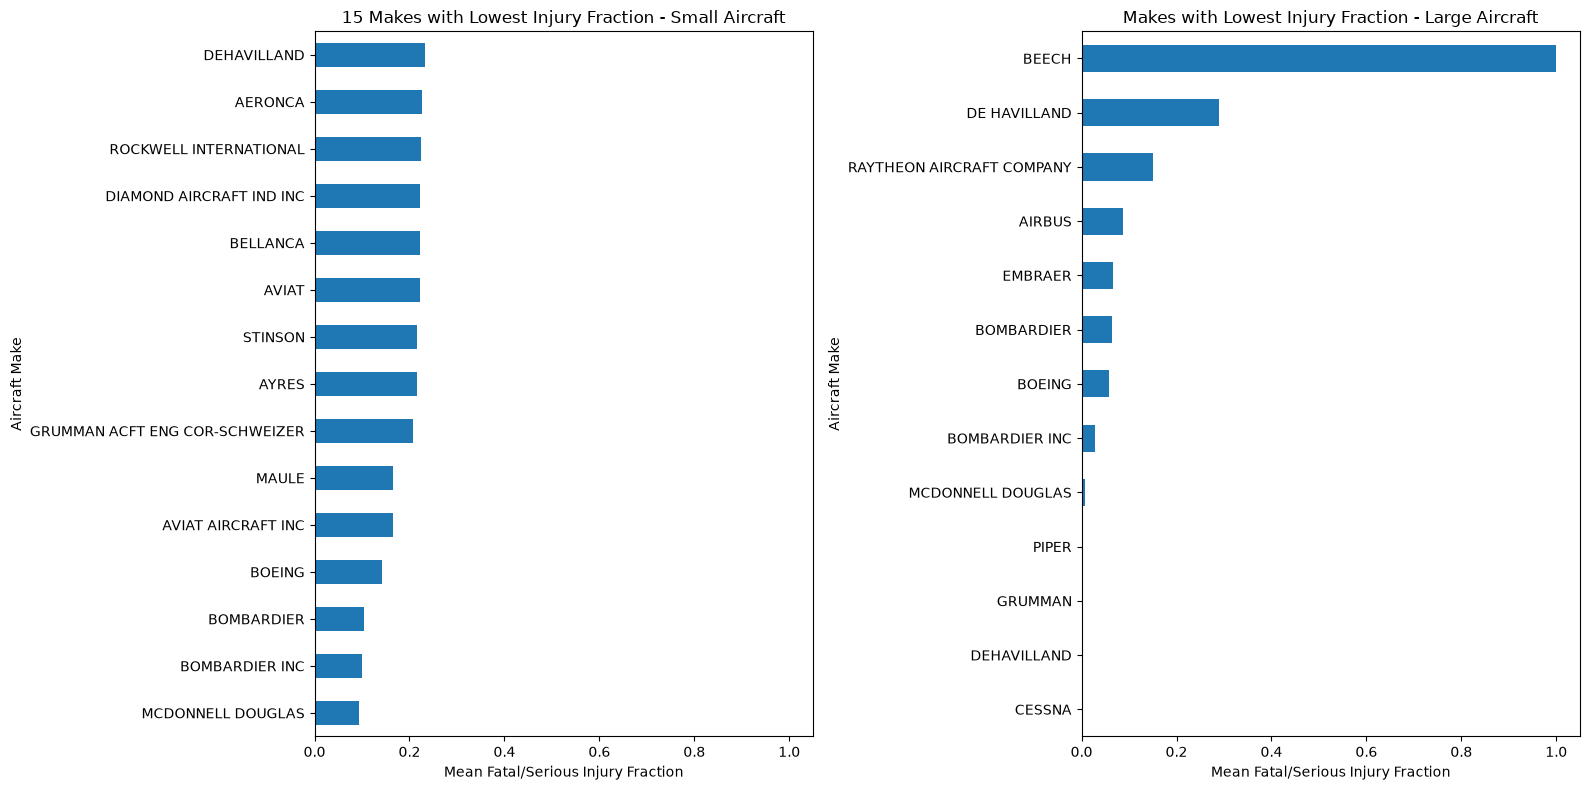

In [8]:
# Create two plots 
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True)

# Small aircraft
small_top15.sort_values().plot(
    kind='barh',
    ax=axes[0]
)

axes[0].set_title('15 Makes with Lowest Injury Fraction - Small Aircraft')
axes[0].set_xlabel('Mean Fatal/Serious Injury Fraction')
axes[0].set_ylabel('Aircraft Make')

# Large aircraft
large_top15.sort_values().plot(
    kind='barh',
    ax=axes[1]
)

axes[1].set_title('Makes with Lowest Injury Fraction - Large Aircraft')
axes[1].set_xlabel('Mean Fatal/Serious Injury Fraction')
axes[1].set_ylabel('Aircraft Make')

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

In [10]:
# Find the 10 makes with the lowest mean injury fractions
small_top10 = small_planes.groupby('Make')['Injury.Fraction'].mean().nsmallest(10)

print(small_top10)

Make
MCDONNELL DOUGLAS                 0.094048
BOMBARDIER INC                    0.100000
BOMBARDIER                        0.103846
BOEING                            0.141973
AVIAT AIRCRAFT INC                0.164474
MAULE                             0.164806
GRUMMAN ACFT ENG COR-SCHWEIZER    0.206897
AYRES                             0.215686
STINSON                           0.216408
AVIAT                             0.221429
Name: Injury.Fraction, dtype: float64


In [11]:
# Keep only the 10 selected makes
small_top10_data = small_planes[small_planes['Make'].isin(small_top10.index)].copy()

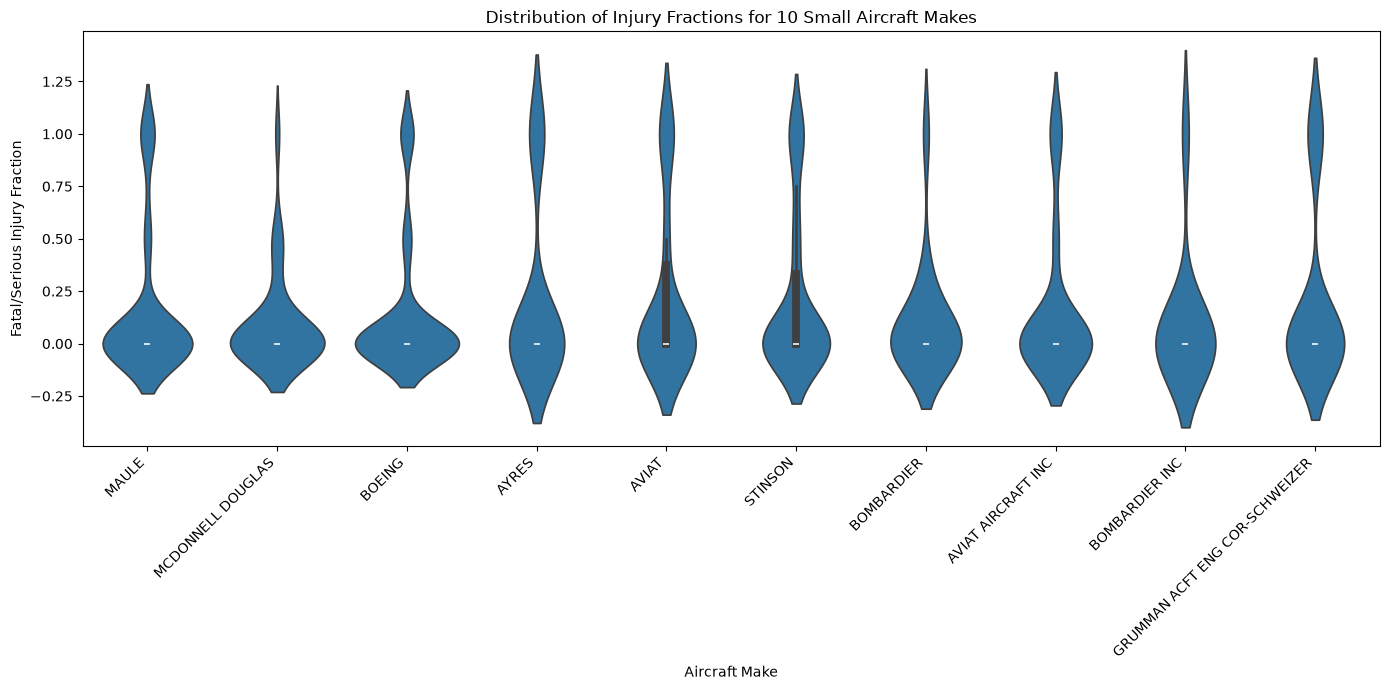

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

sns.violinplot(
    data=small_top10_data,
    x='Make',
    y='Injury.Fraction'
)

plt.title('Distribution of Injury Fractions for 10 Small Aircraft Makes')
plt.xlabel('Aircraft Make')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

In [14]:
large_top10 = large_planes.groupby('Make')['Injury.Fraction'].mean().nsmallest(10)

print(large_top10)

Make
CESSNA               0.000000
DEHAVILLAND          0.000000
GRUMMAN              0.000000
PIPER                0.000000
MCDONNELL DOUGLAS    0.007827
BOMBARDIER INC       0.028038
BOEING               0.056771
BOMBARDIER           0.063701
EMBRAER              0.065274
AIRBUS               0.086249
Name: Injury.Fraction, dtype: float64


In [15]:
large_top10_data = large_planes[large_planes['Make'].isin(large_top10.index)].copy()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

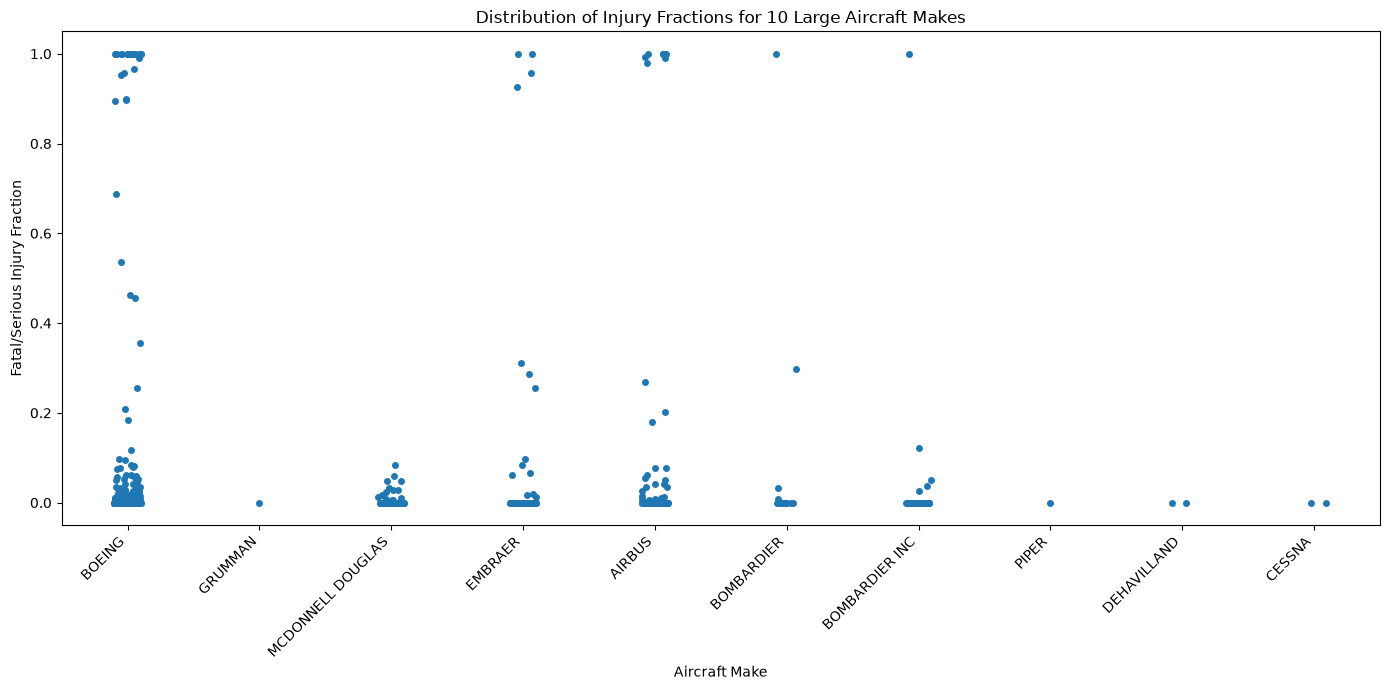

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

sns.stripplot(
    data=large_top10_data,
    x='Make',
    y='Injury.Fraction',
    jitter=True
)

plt.title('Distribution of Injury Fractions for 10 Large Aircraft Makes')
plt.xlabel('Aircraft Make')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

### Findings and Recommendations

The analysis showed differences in fatal/serious injury fractions between small and large aircraft makes. For small aircraft, McDonnell Douglas, Bombardier Inc., and Bombardier had the lowest mean injury fractions. For large aircraft, Cessna, De Havilland, Grumman, and Piper had the lowest mean injury fractions.

The violin and strip plots showed variation in injury rates between accidents involving the same aircraft make. Some makes had consistently low injury fractions, while others showed greater variation.

Based on the injury fractions, the makes with lower values may be considered preferable options. However, recommendations should also consider the fraction of aircraft destroyed, as well as the number of accidents recorded. These findings show associations in the available accident data and do not prove that one aircraft make is safer than another.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

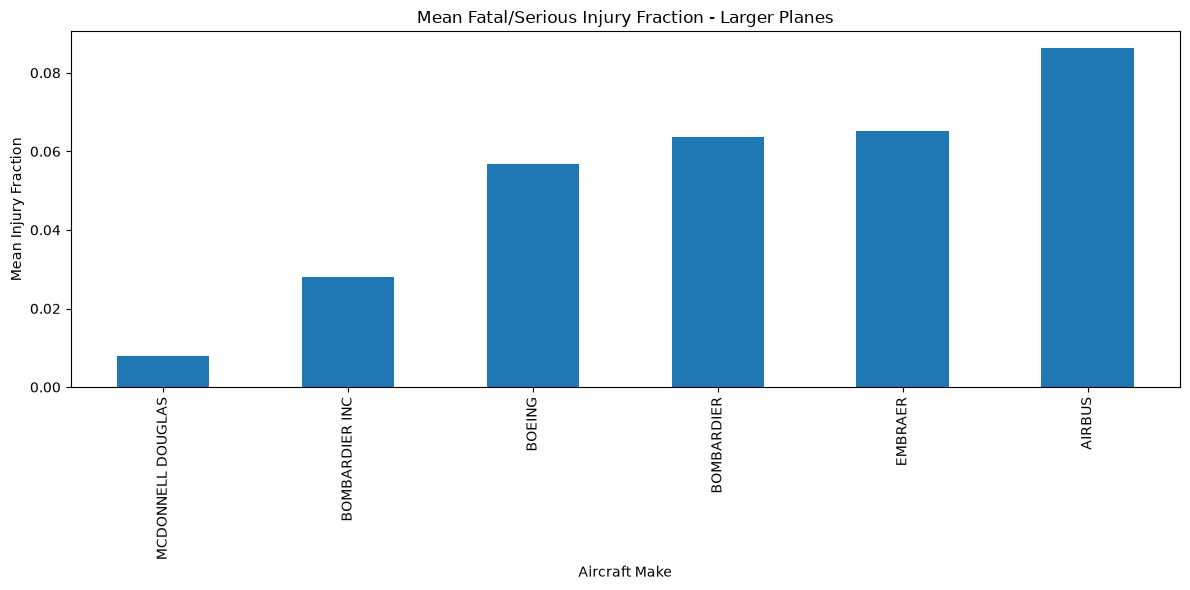

In [18]:
# Group by make and calculate mean injury fraction
# Only include makes with at least 10 accidents

large_make_means = large_planes.groupby('Make').agg(
    Mean_Injury_Fraction=('Injury.Fraction', 'mean'),
    Accident_Count=('Injury.Fraction', 'count')
)

large_make_means = large_make_means[
    large_make_means['Accident_Count'] >= 10
]

# Plot mean injury fractions
plt.figure(figsize=(12, 6))

large_make_means['Mean_Injury_Fraction'].sort_values().plot(kind='bar')

plt.title('Mean Fatal/Serious Injury Fraction - Larger Planes')
plt.xlabel('Aircraft Make')
plt.ylabel('Mean Injury Fraction')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

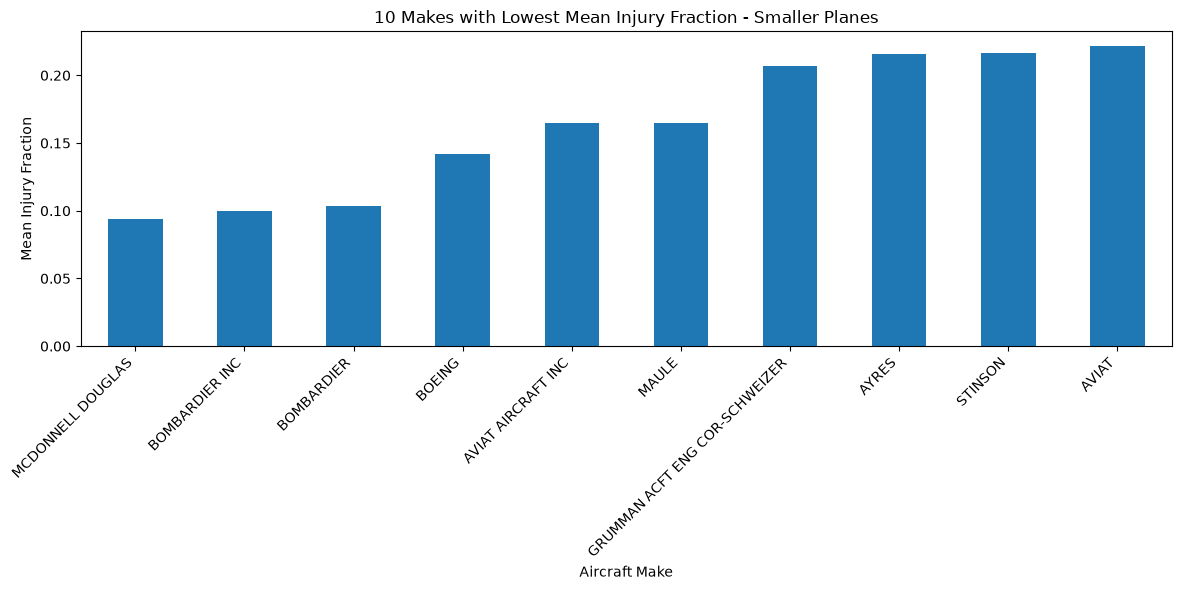

In [17]:
# Group by make and calculate mean injury fraction
# Only include makes with at least 10 accidents

small_make_means = small_planes.groupby('Make').agg(
    Mean_Injury_Fraction=('Injury.Fraction', 'mean'),
    Accident_Count=('Injury.Fraction', 'count')
)

small_make_means = small_make_means[
    small_make_means['Accident_Count'] >= 10
]

# Select the 10 makes with the lowest mean injury fractions
small_top10 = small_make_means.nsmallest(
    10, 'Mean_Injury_Fraction'
)

# Plot mean injury fractions
plt.figure(figsize=(12, 6))

small_top10['Mean_Injury_Fraction'].sort_values().plot(kind='bar')

plt.title('10 Makes with Lowest Mean Injury Fraction - Smaller Planes')
plt.xlabel('Aircraft Make')
plt.ylabel('Mean Injury Fraction')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

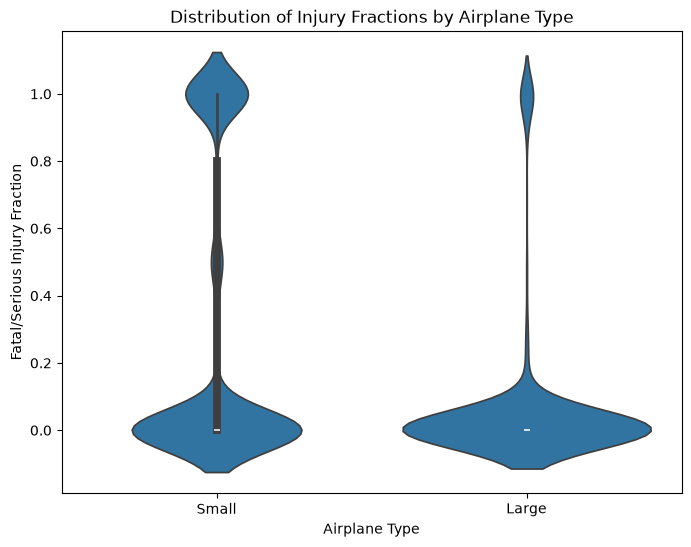

In [19]:
# Combine small and large aircraft data
small_data = small_planes[['Injury.Fraction']].copy()
small_data['Aircraft Type'] = 'Small'

large_data = large_planes[['Injury.Fraction']].copy()
large_data['Aircraft Type'] = 'Large'

combined_data = pd.concat([small_data, large_data])

# Create violin plot
plt.figure(figsize=(8, 6))

sns.violinplot(
    data=combined_data,
    x='Aircraft Type',
    y='Injury.Fraction'
)

plt.title('Distribution of Injury Fractions by Airplane Type')
plt.xlabel('Airplane Type')
plt.ylabel('Fatal/Serious Injury Fraction')
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Discussion of Specific Airplane Types

The analysis showed differences in fatal and serious injury fractions across small and large airplane models. Some models had lower average injury fractions, suggesting better injury outcomes in the recorded accidents. However, injury fractions varied between accidents involving the same model.

For smaller aircraft, the 10 models with the lowest mean injury fractions provided potential options with comparatively better recorded injury outcomes. Larger aircraft also showed differences in injury fractions across models.

These results should be interpreted with caution because accident circumstances, flight conditions, passenger numbers and the number of recorded accidents can influence the results. Therefore, injury fractions alone should not be used as the only measure of aircraft safety.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

In [20]:
#weather analysis
df['Weather.Condition'].value_counts()

Weather.Condition
VMC    14295
IMC      905
Unk      186
UNK       76
Name: count, dtype: int64

In [ ]:
#Calculate injury and damage outcomes by weather
weather_analysis = df.groupby('Weather.Condition').agg(
    Mean_Injury_Fraction=('Injury.Fraction', 'mean'),
    Accident_Count=('Event.Id', 'count')
)

print(weather_analysis)

                   Mean_Injury_Fraction  Accident_Count
Weather.Condition                                      
IMC                            0.628008             905
UNK                            0.219167              76
Unk                            0.497115             186
VMC                            0.233090           14295


In [30]:
df['Aircraft.damage'].value_counts()

Aircraft.damage
Substantial    14230
Destroyed       1827
Minor            676
Unknown           82
Name: count, dtype: int64

In [31]:
# Count accidents involving destroyed aircraft
df['Aircraft.Destroyed'] = (
    df['Aircraft.damage'].str.strip().str.lower() == 'destroyed'
).astype(int)

# Calculate injury and destruction statistics by weather
weather_analysis = df.groupby('Weather.Condition').agg(
    Mean_Injury_Fraction=('Injury.Fraction', 'mean'),
    Destroyed_Fraction=('Aircraft.Destroyed', 'mean'),
    Accident_Count=('Event.Id', 'count')
)

print(weather_analysis)

                   Mean_Injury_Fraction  Destroyed_Fraction  Accident_Count
Weather.Condition                                                          
IMC                            0.628008            0.348066             905
UNK                            0.219167            0.236842              76
Unk                            0.497115            0.274194             186
VMC                            0.233090            0.070864           14295


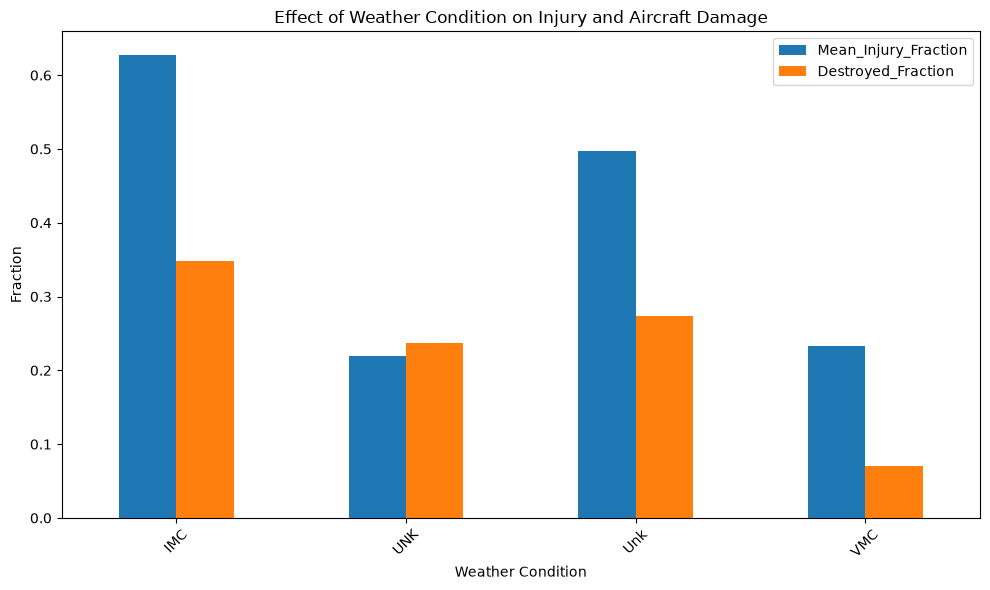

In [32]:
weather_analysis[['Mean_Injury_Fraction', 'Destroyed_Fraction']].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Effect of Weather Condition on Injury and Aircraft Damage')
plt.xlabel('Weather Condition')
plt.ylabel('Fraction')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Weather Condition

Weather conditions appeared to be associated with differences in aircraft damage and injury outcomes. Accidents occurring under Instrument Meteorological Conditions (IMC) had the highest mean fatal/serious injury fraction (0.628) and destroyed fraction (0.348). In contrast, Visual Meteorological Conditions (VMC) had lower values of 0.233 and 0.071, respectively.

This suggests that accidents occurring under IMC were associated with more severe outcomes than those under VMC. However, the analysis does not establish causation. The unknown weather categories had fewer recorded accidents, so their results should be interpreted cautiously.

In [33]:
#ENGINE
df['Number.of.Engines'].value_counts(dropna=False)

Number.of.Engines
1.0    13222
2.0     2470
NaN     2089
4.0       67
3.0       26
0.0        5
Name: count, dtype: int64

In [34]:
engine_analysis = df.groupby('Number.of.Engines').agg(
    Mean_Injury_Fraction=('Injury.Fraction', 'mean'),
    Destroyed_Fraction=('Aircraft.Destroyed', 'mean'),
    Accident_Count=('Event.Id', 'count')
)

print(engine_analysis)

                   Mean_Injury_Fraction  Destroyed_Fraction  Accident_Count
Number.of.Engines                                                          
0.0                            0.285714            0.200000               5
1.0                            0.255847            0.077144           13222
2.0                            0.276332            0.135628            2470
3.0                            0.082690            0.038462              26
4.0                            0.139095            0.089552              67


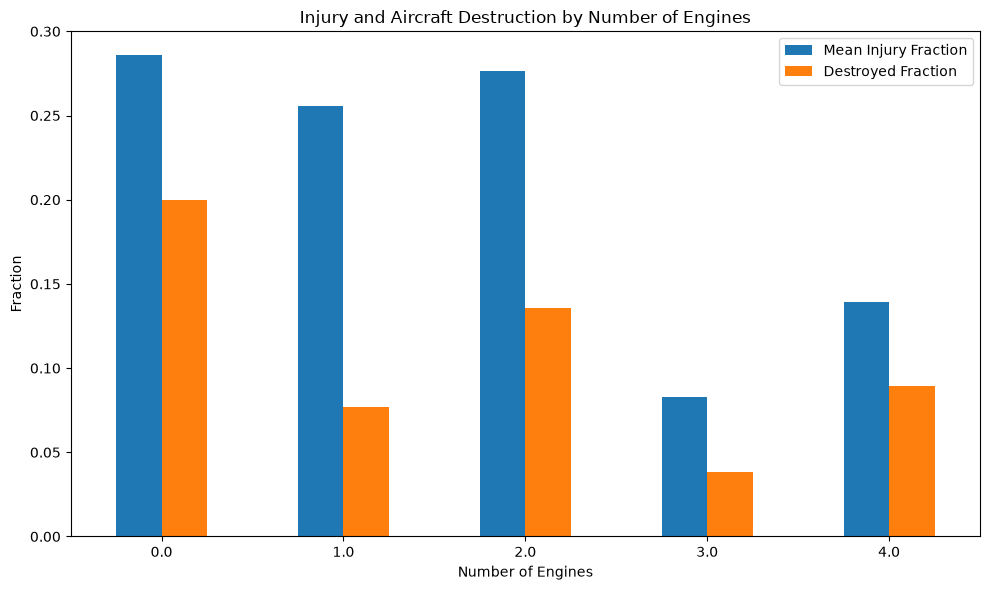

In [35]:
engine_analysis[['Mean_Injury_Fraction', 'Destroyed_Fraction']].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Injury and Aircraft Destruction by Number of Engines')
plt.xlabel('Number of Engines')
plt.ylabel('Fraction')
plt.xticks(rotation=0)
plt.legend(['Mean Injury Fraction', 'Destroyed Fraction'])
plt.tight_layout()
plt.show()



The analysis showed differences in injury and aircraft destruction fractions according to the number of engines. Two-engine aircraft had a slightly higher mean injury fraction (0.276) than single-engine aircraft (0.256). They also had a higher destruction fraction (0.136 compared with 0.077). Aircraft with three or four engines had lower recorded fractions, but these groups had very few accidents. Therefore, their results may not be representative. Overall, the findings suggest that the number of engines may be associated with accident outcomes, but other factors, including weather and flight conditions, should also be considered. These results do not establish that having more engines causes better safety outcomes.